# Time-aware · 00 — Data preparation

Identical for both strategies (random K-fold and time-aware): only the output folder differs, so both start from the same data.

| § | Step |
|---|---|
| 1 | Load `train.csv` and split by date (train < 23 Oct 2018, test ≥ 23 Oct) |
| 2 | Feature engineering and trailing volumes |
| 3 | Sparsity rule and the 48-candidate list |
| 4 | Category maps; write the train, test and label files |
| 5 | Sanity checks |
| 6 | Manifest: column lists, category maps, file hashes, package versions |
| 7 | Drift diagnostics (train period only) |

Test labels are written to their own file and are not looked at here: only the test row count is printed.

In [1]:
import gc
import hashlib
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import lightgbm
import catboost

from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

STRATEGY = 'time_cv'
SEED = 42
RAW = Path('../Data/Raw')
DATA_OUT = Path('../Data/Processed_time_cv')
DATA_OUT.mkdir(parents=True, exist_ok=True)

TARGET = 'loan_default'
ID_COL = 'UniqueID'
DATE_COL = 'disb_date'

CUT_DATE = pd.Timestamp('2018-10-23')    # train: before, test: on or after
VOLUME_WINDOW_DAYS = 7
SPARSE_MAX = 0.97

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
np.random.seed(SEED)

## 1. Load and split by date

Train = `disb_date < 2018-10-23`, test = `disb_date >= 2018-10-23`.

In [2]:
labelled = pd.read_csv(RAW / 'train.csv')
labelled[DATE_COL] = pd.to_datetime(labelled['DisbursalDate'], format='%d-%m-%y')
assert labelled[ID_COL].is_unique, 'duplicate loans in the labelled data'

is_test = (labelled[DATE_COL] >= CUT_DATE).to_numpy()
n_train, n_test = int((~is_test).sum()), int(is_test.sum())

train_default_rate = float(labelled.loc[~is_test, TARGET].mean())
print(f'train rows {n_train:,}  default rate {train_default_rate:.4f}')
print(f'test rows  {n_test:,}')

train rows 182,501  default rate 0.2063
test rows  50,653


## 2. Feature engineering

Row-wise transforms (age at disbursal, parsed durations, ratios, flags), calendar position, and trailing 7-day origination volume per dealer, branch and employee. Volume tables use dates and IDs of **all labelled disbursals** (train and test); outcomes are never used.

In [3]:
def duration_to_months(s: pd.Series) -> pd.Series:
    """'3yrs 7mon' -> 43.0; NaN if the pattern does not match."""
    parts = s.astype(str).str.extract(r'(\d+)\s*yrs?\s*(\d+)\s*mon')
    return parts[0].astype(float) * 12 + parts[1].astype(float)


def safe_ratio(num: pd.Series, den: pd.Series) -> np.ndarray:
    """num / den, NaN where den <= 0."""
    return np.where(den > 0, num / den.replace(0, np.nan), np.nan)


KYC_FLAGS = ['Aadhar_flag', 'PAN_flag', 'VoterID_flag', 'Driving_flag', 'Passport_flag']

DROP_STRUCTURAL = [
    'UniqueID', 'MobileNo_Avl_Flag',
    'Date.of.Birth', 'DisbursalDate',
    'AVERAGE.ACCT.AGE', 'CREDIT.HISTORY.LENGTH',
]

CATEGORICAL = [
    'branch_id', 'supplier_id', 'manufacturer_id', 'Current_pincode_ID',
    'State_ID', 'Employee_code_ID',
    'Employment.Type', 'PERFORM_CNS.SCORE.DESCRIPTION',
]

DATE_FEATS = ['disb_day_of_month', 'days_to_month_end']
VOLUME_KEYS = ['supplier_id', 'branch_id', 'Employee_code_ID']
VOL_COLS = [f'{k}_loans_{VOLUME_WINDOW_DAYS}d' for k in VOLUME_KEYS]


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Row-wise feature engineering plus calendar position. Target-free."""
    out = df.copy()

    dob = pd.to_datetime(out['Date.of.Birth'], format='%d-%m-%y')
    disbursal = pd.to_datetime(out['DisbursalDate'], format='%d-%m-%y')
    dob = dob.where(~(dob > disbursal), dob - pd.DateOffset(years=100))
    out['age_at_disbursal'] = ((disbursal - dob).dt.days / 365.25).round(1)

    out['disb_day_of_month'] = disbursal.dt.day.astype('int8')
    out['days_to_month_end'] = (disbursal.dt.days_in_month - disbursal.dt.day).astype('int8')

    out['Employment.Type'] = out['Employment.Type'].fillna('unknown')
    out['PERFORM_CNS.SCORE.DESCRIPTION'] = out['PERFORM_CNS.SCORE.DESCRIPTION'].str.strip()

    out['avg_acct_age_months'] = duration_to_months(out['AVERAGE.ACCT.AGE'])
    out['credit_history_months'] = duration_to_months(out['CREDIT.HISTORY.LENGTH'])

    out['pri_overdue_share'] = safe_ratio(out['PRI.OVERDUE.ACCTS'], out['PRI.NO.OF.ACCTS'])
    out['pri_active_share'] = safe_ratio(out['PRI.ACTIVE.ACCTS'], out['PRI.NO.OF.ACCTS'])
    out['pri_utilisation'] = safe_ratio(out['PRI.CURRENT.BALANCE'], out['PRI.SANCTIONED.AMOUNT'])
    out['pri_disb_to_sanc'] = safe_ratio(out['PRI.DISBURSED.AMOUNT'], out['PRI.SANCTIONED.AMOUNT'])
    out['total_instal_amt'] = out['PRIMARY.INSTAL.AMT'] + out['SEC.INSTAL.AMT']
    out['loan_to_instal'] = safe_ratio(out['disbursed_amount'], out['total_instal_amt'])
    out['new_loan_vs_balance'] = safe_ratio(out['disbursed_amount'], out['PRI.CURRENT.BALANCE'])
    out['delinq_share_6m'] = safe_ratio(out['DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS'], out['PRI.ACTIVE.ACCTS'])

    out['has_bureau_score'] = (out['PERFORM_CNS.SCORE'] > 0).astype('int8')
    out['is_new_to_credit'] = ((out['PRI.NO.OF.ACCTS'] == 0) & (out['SEC.NO.OF.ACCTS'] == 0)).astype('int8')
    out['has_any_overdue'] = ((out['PRI.OVERDUE.ACCTS'] > 0) | (out['SEC.OVERDUE.ACCTS'] > 0)).astype('int8')
    out['has_recent_delinquency'] = (out['DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS'] > 0).astype('int8')
    out['has_recent_new_accts'] = (out['NEW.ACCTS.IN.LAST.SIX.MONTHS'] > 0).astype('int8')
    out['has_inquiries'] = (out['NO.OF_INQUIRIES'] > 0).astype('int8')
    out['has_secondary_accts'] = (out['SEC.NO.OF.ACCTS'] > 0).astype('int8')
    out['n_kyc_docs'] = out[KYC_FLAGS].sum(axis=1).astype('int8')

    return out


def trailing_volume(events: pd.DataFrame, key: str, window: int = VOLUME_WINDOW_DAYS) -> pd.DataFrame:
    """keys x dates table: loans per key in the `window` days strictly before each date.
    NaN where the window reaches back before the first date in `events`."""
    daily = events.groupby([key, DATE_COL]).size().unstack(fill_value=0)
    all_dates = pd.date_range(events[DATE_COL].min(), events[DATE_COL].max())
    daily = daily.reindex(columns=all_dates, fill_value=0).astype('float32')
    return daily.T.shift(1).rolling(window, min_periods=window).sum().T


def add_volume_features(df: pd.DataFrame, tables: dict) -> None:
    """In place: look up each row's trailing volume for every key."""
    for key, table in tables.items():
        rows = table.index.get_indexer(df[key])
        cols = table.columns.get_indexer(df[DATE_COL])
        df[f'{key}_loans_{VOLUME_WINDOW_DAYS}d'] = table.to_numpy()[rows, cols]


# Every labelled disbursal, Aug-Oct. Dates and IDs only - outcomes are never used.
events = labelled[[DATE_COL] + VOLUME_KEYS]
VOLUME_TABLES = {key: trailing_volume(events, key) for key in VOLUME_KEYS}
del events
gc.collect()

for key, table in VOLUME_TABLES.items():
    print(f'{key:18s} {table.shape[0]:>5} keys x {table.shape[1]} days')

eng = build_features(labelled)
add_volume_features(eng, VOLUME_TABLES)
del labelled, VOLUME_TABLES
gc.collect()

supplier_id         2953 keys x 92 days
branch_id             82 keys x 92 days
Employee_code_ID    3270 keys x 92 days


0

## 3. Sparsity rule and candidate list

Numeric columns that are zero in more than 97% of **train** rows are dropped (no target involved).

In [4]:
NUMERIC_ALL = [c for c in eng.columns if c not in DROP_STRUCTURAL + CATEGORICAL + [TARGET, DATE_COL]]
zero_share = (eng.loc[~is_test, NUMERIC_ALL] == 0).mean()
sparse = zero_share[zero_share > SPARSE_MAX].sort_values(ascending=False)
print(f'Dropped as sparse (> {SPARSE_MAX:.0%} zeros): {len(sparse)}')
print((sparse * 100).round(2).to_string())

NUMERIC = [c for c in NUMERIC_ALL if c not in sparse.index]
SAVE_COLS = [ID_COL, DATE_COL] + NUMERIC + CATEGORICAL
print(f'\n{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical = {len(NUMERIC) + len(CATEGORICAL)} candidates')

Dropped as sparse (> 97% zeros): 10
Passport_flag            99.78
SEC.OVERDUE.ACCTS        99.34
SEC.INSTAL.AMT           98.89
SEC.CURRENT.BALANCE      98.33
SEC.DISBURSED.AMOUNT     98.15
SEC.SANCTIONED.AMOUNT    98.14
SEC.ACTIVE.ACCTS         98.10
Driving_flag             97.53
SEC.NO.OF.ACCTS          97.09
has_secondary_accts      97.09

40 numeric + 8 categorical = 48 candidates


## 4. Category maps and output files

Category map per column: sorted unique **train** values (as strings); the list index is the code. Raw values are stored in the CSV files; later notebooks encode with the map and give unseen levels code `-2`. The test file has no target column; labels go to `test_labels.csv`.

In [5]:
train = eng.loc[~is_test, SAVE_COLS + [TARGET]].reset_index(drop=True)
test_full = eng.loc[is_test, SAVE_COLS + [TARGET]].reset_index(drop=True)
del eng
gc.collect()

category_maps = {col: sorted(train[col].astype(str).unique()) for col in CATEGORICAL}

train.to_csv(DATA_OUT / 'train_features.csv', index=False)
test_full[SAVE_COLS].to_csv(DATA_OUT / 'test_features.csv', index=False)
test_full[[ID_COL, TARGET]].to_csv(DATA_OUT / 'test_labels.csv', index=False)
del test_full
gc.collect()

sha = {f: hashlib.sha256((DATA_OUT / f).read_bytes()).hexdigest()
       for f in ['train_features.csv', 'test_features.csv', 'test_labels.csv']}
for f, h in sha.items():
    print(f'{f:22s} {h}')

train_features.csv     a05a5fb7aa2924e43d5da8657d0dc50a8cbb0aaa9a328541a865ff3c6354521d
test_features.csv      3634e87ee4e6561262d750fe28bd3248cbf2df27a92a7ff51c2c45682847c542
test_labels.csv        f751dcb07ebde408413b762eef443c9bcbf9fc771931391e62ecc9e7714378f0


## 5. Sanity checks

Asserts: age range, duration parsing, volume NaN only in the first 7 days of August, train dates before the cut; the test file has no target column; categorical columns have no missing values.

In [6]:
first_full_window = train[DATE_COL].min() + pd.Timedelta(days=VOLUME_WINDOW_DAYS)
assert train[DATE_COL].max() < CUT_DATE, 'test rows leaked into the training frame'
assert train['age_at_disbursal'].between(17, 90).all(), 'implausible age produced'
assert train[['avg_acct_age_months', 'credit_history_months']].isna().sum().sum() == 0, 'duration parse failed'
assert train.loc[train[DATE_COL] >= first_full_window, VOL_COLS].notna().all().all(), 'volume gap after week 1'
assert train.loc[train[DATE_COL] < first_full_window, VOL_COLS].isna().all().all(), 'volume set inside week 1'

test_header = pd.read_csv(DATA_OUT / 'test_features.csv', nrows=0).columns.tolist()
assert TARGET not in test_header, 'test_features.csv contains the target'
assert train[CATEGORICAL].isna().sum().sum() == 0, 'categorical columns have missing values'

y = train[TARGET].to_numpy()
period = pd.cut(train[DATE_COL],
                bins=[pd.Timestamp('2018-08-01'), pd.Timestamp('2018-09-01'), pd.Timestamp('2018-10-01'), CUT_DATE],
                right=False, labels=['Aug', 'Sep', 'Oct 1-22'])
PERIODS = list(period.cat.categories)

print(f'train: {train.shape}  {train[DATE_COL].min().date()} -> {train[DATE_COL].max().date()}')
print(train.groupby(period, observed=True)[TARGET].agg(rows='size', default_rate='mean').round(4))

# float32 from here on; the files above were written from float64
for c in train.select_dtypes('float64').columns:
    train[c] = train[c].astype('float32')

train: (182501, 51)  2018-08-01 -> 2018-10-22
            rows  default_rate
disb_date                     
Aug        68002        0.2157
Sep        66788        0.1919
Oct 1-22   47711        0.2131


## 6. Manifest

In [7]:
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'lightgbm': lightgbm.__version__, 'catboost': catboost.__version__}
out_manifest = {
    'strategy': STRATEGY,
    'cut_date': str(CUT_DATE.date()),
    'rows': {'train': n_train, 'test': n_test},
    'train_default_rate': train_default_rate,
    'numeric_columns': NUMERIC,
    'categorical_columns': CATEGORICAL,
    'sparse_dropped': list(sparse.index),
    'sparse_zero_share': {k: float(v) for k, v in sparse.items()},
    'category_maps': category_maps,
    'sha256': sha,
    'versions': versions,
    'column_order': SAVE_COLS + [TARGET],
}
(DATA_OUT / 'manifest.json').write_text(json.dumps(out_manifest, indent=2))
print('Wrote manifest.json; versions:', versions)

Wrote manifest.json; versions: {'python': '3.11.3', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'catboost': '1.2.10'}


## 7. Drift diagnostics — train period only

Weekly volume and default rate; default rate by LTV, score and age band per month; signed univariate Gini per month; PSI August vs 1–22 October; adversarial validation (calendar and volume features excluded). Run on the 48 candidates.

            loans  default_rate
disb_date                      
2018-07-30   4827         23.24
2018-08-06  12549         23.67
2018-08-13  13301         19.84
2018-08-20  16847         20.62
2018-08-27  20478         21.78
2018-09-03  10423         20.39
2018-09-10  13855         18.17
2018-09-17  19342         18.06
2018-09-24  23168         20.20
2018-10-01   6503         21.08
2018-10-08  16786         21.56
2018-10-15  18494         21.22
2018-10-22   5928         21.15


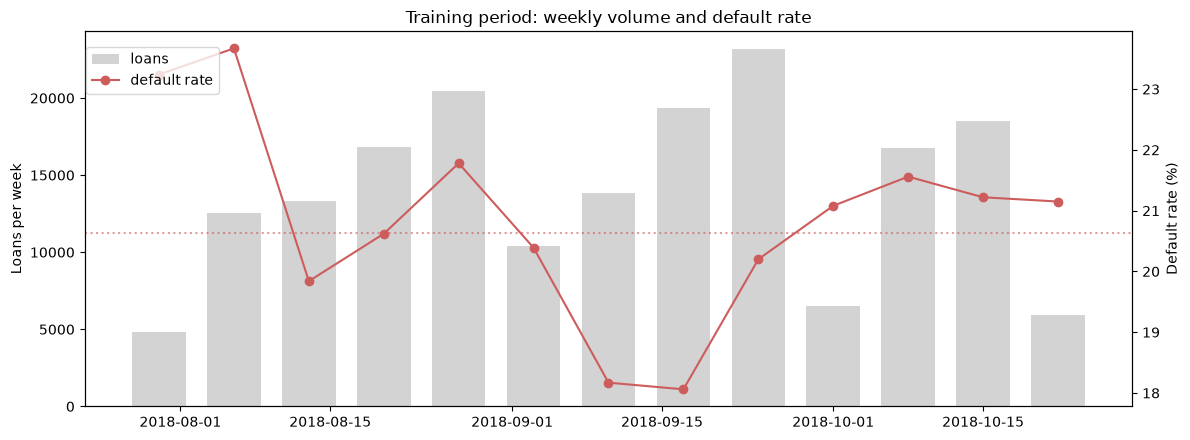

In [8]:
week = train[DATE_COL].dt.to_period('W').dt.start_time
weekly = train.groupby(week)[TARGET].agg(loans='size', default_rate='mean')
weekly['default_rate'] = (weekly['default_rate'] * 100).round(2)
print(weekly.to_string())

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(weekly.index, weekly['loans'], width=5, color='lightgray', label='loans')
ax1.set_ylabel('Loans per week')
ax2 = ax1.twinx()
ax2.plot(weekly.index, weekly['default_rate'], marker='o', color='indianred', label='default rate')
ax2.axhline(y.mean() * 100, color='indianred', linestyle=':', alpha=0.6)
ax2.set_ylabel('Default rate (%)')
ax1.set_title('Training period: weekly volume and default rate')
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.9))
plt.tight_layout()
plt.show()

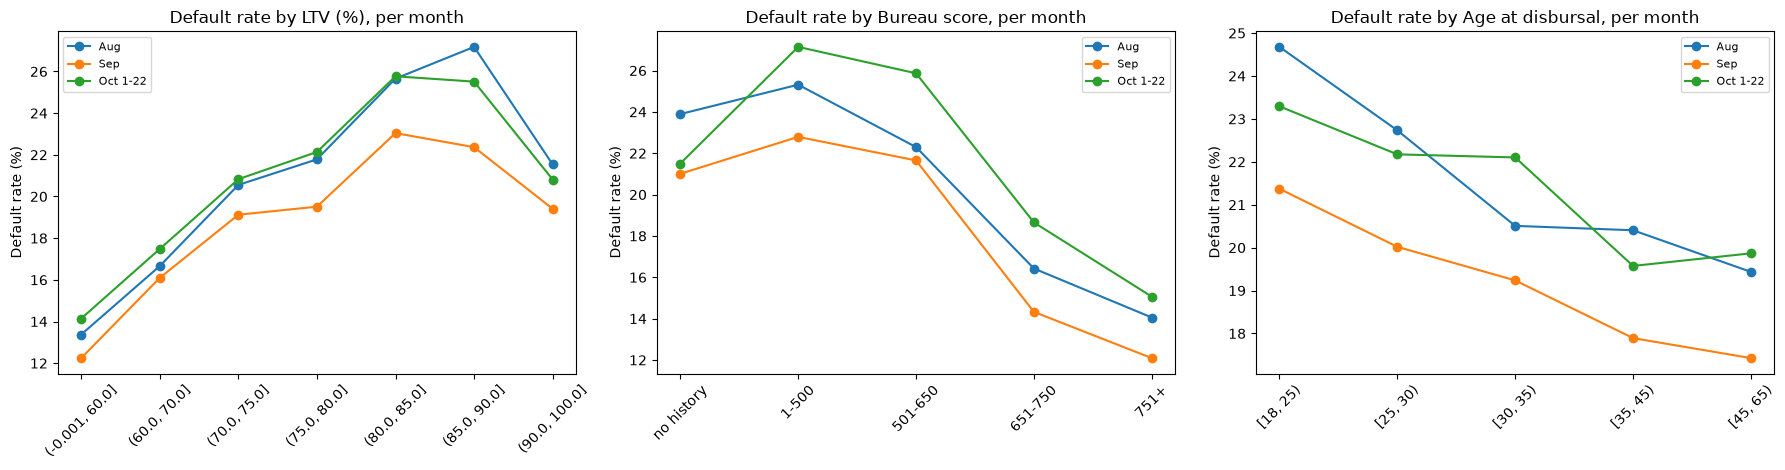

In [9]:
# Do the core relationships hold in every month?
bands = {
    'LTV (%)': pd.cut(train['ltv'], [0, 60, 70, 75, 80, 85, 90, 100], include_lowest=True),
    'Bureau score': pd.cut(train['PERFORM_CNS.SCORE'], [-1, 0, 500, 650, 750, 900],
                           labels=['no history', '1-500', '501-650', '651-750', '751+']),
    'Age at disbursal': pd.cut(train['age_at_disbursal'], [18, 25, 30, 35, 45, 65], right=False),
}

band_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (name, band) in zip(axes, bands.items()):
    tbl = (train.assign(band=band, period=period)
                .groupby(['band', 'period'], observed=True)[TARGET].mean().unstack() * 100)
    band_tables[name] = {str(b): {str(p): (None if pd.isna(v) else float(v)) for p, v in row.items()}
                         for b, row in tbl.iterrows()}
    for p in PERIODS:
        ax.plot(tbl.index.astype(str), tbl[p], marker='o', label=p)
    ax.set_title(f'Default rate by {name}, per month')
    ax.set_ylabel('Default rate (%)')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Signed univariate Gini per month (top 25 by average strength):
                             Aug    Sep  Oct 1-22  range  sign_flip  mean_abs
ltv                        0.159  0.130     0.141  0.029      False     0.143
disbursed_amount           0.131  0.111     0.131  0.020      False     0.124
pri_overdue_share          0.112  0.119     0.105  0.014      False     0.112
new_loan_vs_balance        0.100  0.078     0.094  0.022      False     0.091
delinq_share_6m            0.081  0.093     0.085  0.012      False     0.086
PERFORM_CNS.SCORE         -0.103 -0.096    -0.045  0.058      False     0.081
loan_to_instal             0.082  0.055     0.062  0.027      False     0.066
PRI.NO.OF.ACCTS           -0.085 -0.073    -0.014  0.070      False     0.058
credit_history_months     -0.081 -0.070    -0.017  0.064      False     0.056
age_at_disbursal          -0.062 -0.054    -0.047  0.015      False     0.054
pri_disb_to_sanc           0.052  0.054     0.056  0.004      False     0.054
P

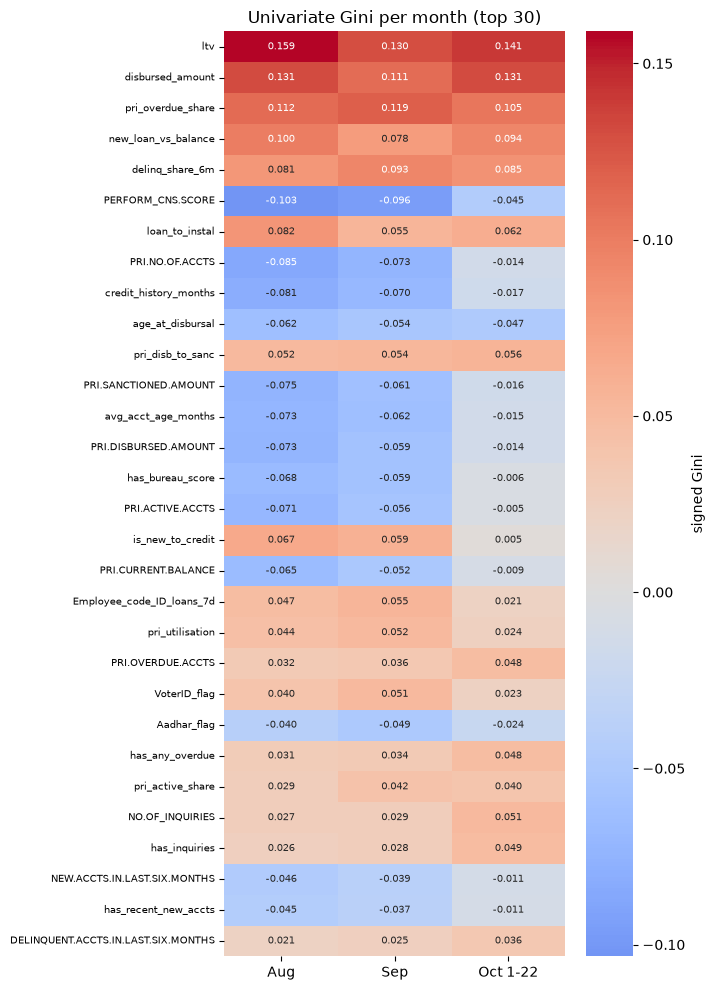

In [10]:
# Univariate Gini per month: signed, so a sign flip means the direction of the relationship reversed.
def signed_gini(x: np.ndarray, t: np.ndarray) -> float:
    m = ~np.isnan(x)
    if m.sum() < 500 or np.unique(t[m]).size < 2 or np.unique(x[m]).size < 2:
        return np.nan
    return 2 * roc_auc_score(t[m], x[m]) - 1


gini = pd.DataFrame({
    col: {p: signed_gini(train[col].to_numpy(dtype=float)[(period == p).to_numpy()],
                         y[(period == p).to_numpy()]) for p in PERIODS}
    for col in NUMERIC
}).T

signs = np.sign(gini[PERIODS].where(gini[PERIODS].abs() > 0.01))
gini['range'] = gini[PERIODS].max(axis=1) - gini[PERIODS].min(axis=1)
gini['sign_flip'] = (signs.max(axis=1) > 0) & (signs.min(axis=1) < 0)
gini['mean_abs'] = gini[PERIODS].abs().mean(axis=1)
gini = gini.reindex(gini['mean_abs'].sort_values(ascending=False).index)

print('Signed univariate Gini per month (top 25 by average strength):')
print(gini.head(25).round(3).to_string())
print(f'\nFeatures whose direction flips between months: {gini.index[gini["sign_flip"]].tolist()}')

fig, ax = plt.subplots(figsize=(7, 10))
sns.heatmap(gini[PERIODS].head(30), cmap='coolwarm', center=0, annot=True, fmt='.3f',
            annot_kws={'size': 7}, cbar_kws={'label': 'signed Gini'}, ax=ax)
ax.set_title('Univariate Gini per month (top 30)')
ax.tick_params(axis='y', labelsize=7)
plt.tight_layout()
plt.show()

band
stable (<0.1)          43
major (>0.25)           3
moderate (0.1-0.25)     2 

                                  psi                 band
days_to_month_end              3.2394        major (>0.25)
disb_day_of_month              2.8321        major (>0.25)
asset_cost                     0.5757        major (>0.25)
disbursed_amount               0.1908  moderate (0.1-0.25)
branch_id                      0.1232  moderate (0.1-0.25)
State_ID                       0.0949        stable (<0.1)
supplier_id                    0.0587        stable (<0.1)
ltv                            0.0389        stable (<0.1)
supplier_id_loans_7d           0.0300        stable (<0.1)
Employee_code_ID_loans_7d      0.0196        stable (<0.1)
branch_id_loans_7d             0.0131        stable (<0.1)
Current_pincode_ID             0.0114        stable (<0.1)
manufacturer_id                0.0088        stable (<0.1)
Employee_code_ID               0.0066        stable (<0.1)
PERFORM_CNS.SCORE.DESCRIPTION 

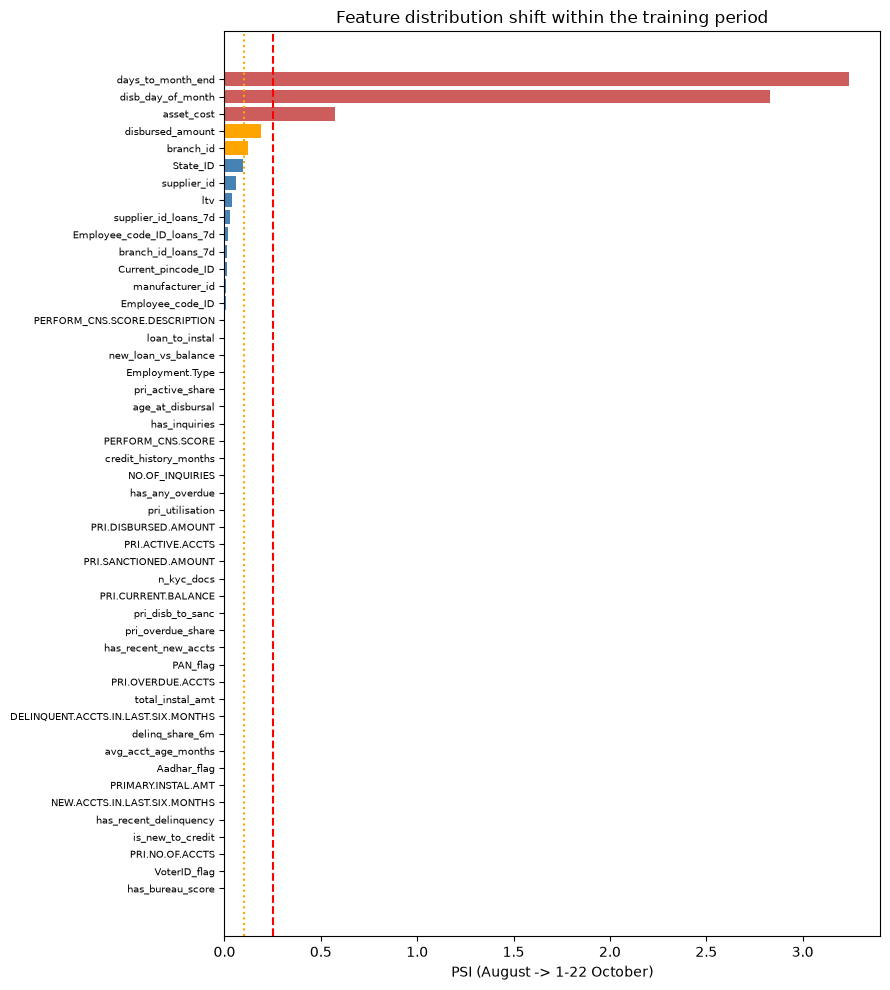

In [11]:
# Population Stability Index, August (reference) vs 1-22 October.
RARE_MIN_COUNT = 100


def ref_bins(ref: pd.Series, q: int = 10):
    """Decile edges fitted on the reference sample; None if too few distinct values to bin."""
    valid = ref.dropna()
    if valid.nunique() < 3:
        return None
    _, edges = pd.qcut(valid, q, retbins=True, duplicates='drop')
    if len(edges) < 3:
        return None
    edges = edges.copy()
    edges[0], edges[-1] = -np.inf, np.inf
    return edges


def to_labels(s: pd.Series, edges) -> np.ndarray:
    if edges is None:
        return np.where(s.isna(), 'MISSING', s.astype(str))
    return np.where(s.isna(), 'MISSING', pd.cut(s, bins=edges).astype(str))


def psi_from_labels(ref_lab, cur_lab, eps: float = 1e-4) -> float:
    r = pd.Series(ref_lab).value_counts(normalize=True)
    c = pd.Series(cur_lab).value_counts(normalize=True)
    idx = r.index.union(c.index)
    r, c = r.reindex(idx, fill_value=0) + eps, c.reindex(idx, fill_value=0) + eps
    return float(((c - r) * np.log(c / r)).sum())


def psi(ref: pd.Series, cur: pd.Series, categorical: bool) -> float:
    if categorical:
        counts = ref.value_counts()
        keep = set(counts[counts >= RARE_MIN_COUNT].index)
        lab = lambda s: np.where(s.isin(keep), s.astype(str), 'RARE')
        return psi_from_labels(lab(ref), lab(cur))
    edges = ref_bins(ref)
    return psi_from_labels(to_labels(ref, edges), to_labels(cur, edges))


ref_mask, cur_mask = (period == 'Aug').to_numpy(), (period == 'Oct 1-22').to_numpy()
psi_rows = {}
for col in NUMERIC + CATEGORICAL:
    ref, cur = train.loc[ref_mask, col], train.loc[cur_mask, col]
    if col in VOL_COLS:   # first week of August has no complete window - compare complete windows only
        ref, cur = ref.dropna(), cur.dropna()
    psi_rows[col] = psi(ref, cur, categorical=col in CATEGORICAL)

psi_table = pd.Series(psi_rows, name='psi').sort_values(ascending=False).to_frame()
psi_table['band'] = pd.cut(psi_table['psi'], [-np.inf, 0.1, 0.25, np.inf],
                           labels=['stable (<0.1)', 'moderate (0.1-0.25)', 'major (>0.25)'])
print(psi_table['band'].value_counts().to_string(), '\n')
print(psi_table.head(20).round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 10))
s = psi_table['psi'].sort_values()
ax.barh(s.index, s.values, color=['indianred' if v > 0.25 else 'orange' if v > 0.1 else 'steelblue'
                                  for v in s.values])
ax.axvline(0.1, color='orange', linestyle=':')
ax.axvline(0.25, color='red', linestyle='--')
ax.set_xlabel('PSI (August -> 1-22 October)')
ax.set_title('Feature distribution shift within the training period')
ax.tick_params(axis='y', labelsize=7)
plt.tight_layout()
plt.show()

In [12]:
# Adversarial validation: can CatBoost tell an August loan from an October loan?
# Calendar and volume features are excluded - they encode time by construction.
ADV_FEATS = [c for c in NUMERIC + CATEGORICAL if c not in DATE_FEATS + VOL_COLS]
adv_mask = ref_mask | cur_mask
adv_X = train.loc[adv_mask, ADV_FEATS]
adv_y = cur_mask[adv_mask].astype(int)
adv_cat_idx = [ADV_FEATS.index(c) for c in CATEGORICAL]

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(adv_X, adv_y, test_size=0.2, stratify=adv_y,
                                              random_state=SEED)
adv_model = CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=6, eval_metric='AUC',
                               random_seed=SEED, task_type='GPU', allow_writing_files=False, verbose=0)
adv_model.fit(Pool(Xa_tr, ya_tr, cat_features=adv_cat_idx),
              eval_set=Pool(Xa_te, ya_te, cat_features=adv_cat_idx),
              early_stopping_rounds=100, use_best_model=True)
adv_auc = roc_auc_score(ya_te, adv_model.predict_proba(Pool(Xa_te, cat_features=adv_cat_idx))[:, 1])

adv_imp = pd.Series(adv_model.get_feature_importance(type='PredictionValuesChange'),
                    index=ADV_FEATS).sort_values(ascending=False)
print(f'Adversarial AUC (August vs 1-22 October): {adv_auc:.4f}')
print('  ~0.5 -> the borrower mix did not change;  well above 0.5 -> it did, and the features below say how.\n')
print('Top 15 features separating the two periods (% of importance):')
print((adv_imp / adv_imp.sum() * 100).head(15).round(2).to_string())

del adv_X, Xa_tr, Xa_te, adv_model
gc.collect()

Default metric period is 5 because AUC is/are not implemented for GPU


Adversarial AUC (August vs 1-22 October): 0.9067
  ~0.5 -> the borrower mix did not change;  well above 0.5 -> it did, and the features below say how.

Top 15 features separating the two periods (% of importance):
asset_cost                       32.71
age_at_disbursal                  9.56
manufacturer_id                   9.55
Employee_code_ID                  7.51
ltv                               6.68
disbursed_amount                  6.36
supplier_id                       5.83
branch_id                         5.03
State_ID                          4.71
Current_pincode_ID                1.03
PERFORM_CNS.SCORE                 0.77
credit_history_months             0.77
PERFORM_CNS.SCORE.DESCRIPTION     0.74
Employment.Type                   0.73
avg_acct_age_months               0.66


10722